# Q2 · 04 Test-set evaluation

The final comparison on the 5,000-review **test** split. Six runs are evaluated, each at its best validation checkpoint:

| Model | Runs |
|---|---|
| BiGRU + additive attention (baseline) | seeds 42, 43 |
| RoBERTa, masked mean pooling (the main model) | seeds 42, 43 |
| RoBERTa, first-token pooling (the ablation) | seeds 42, 43 |

**The test set is touched once.** This is the only notebook that loads it. Each run's test predictions are written once to `outputs/results/<run>/test_predictions.jsonl`, and running the notebook again reloads those files instead of predicting again. Nothing here feeds back into training or model selection.

Contents: overall metrics (mean ± std over the two seeds), per-class F1, the pooling ablation, normalised confusion matrices, adjacent vs distant errors, qualitative examples, and token importance for RoBERTa (integrated gradients) next to the BiGRU's attention weights.

**On Kaggle:** import this notebook as usual, then **Add Input → Your Work → Notebooks** and attach the finished versions of `02_bigru.ipynb` and `03_roberta.ipynb`. Their checkpoints are copied in by the first cell. One GPU is enough.

In [1]:
import os
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")
BRANCH = "main"   # the branch to clone when this notebook runs outside the repo (e.g. imported into Kaggle)

root = Path.cwd().resolve()
while not (root / "common").is_dir() and root != root.parent:
    root = root.parent
if not (root / "common").is_dir():
    import subprocess
    root = Path.cwd() / "NLP-Group-Assignment-2"
    if not root.exists():
        subprocess.run(["git", "clone", "-q", "-b", BRANCH,
                        "https://github.com/Akshats-git/NLP-Group-Assignment-2.git", str(root)], check=True)
    os.chdir(root / "Question-2")
sys.path[:0] = [str(root), str(root / "Question-2")]

# Kaggle preinstalls transformers 5.16.1, which fine-tunes RoBERTa badly (see q2/roberta_data.py)
from importlib.metadata import version
from packaging.version import Version
if Version(version("transformers")) < Version("5.20.2"):
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "transformers>=5.20.2"], check=True)

import torch
from common import DEFAULT_SEEDS, get_device

LIMIT = int(os.environ.get("Q2_LIMIT", 0)) or None   # set for a quick run on a random subset
DEVICE = os.environ.get("Q2_DEVICE", "")             # empty picks cuda, then mps, then cpu
print(get_device(DEVICE or None), torch.cuda.device_count(), "GPU(s)", [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())])

from q2.kaggle import import_finished_runs
from q2.train_bigru import BiGRUConfig
from q2.train_roberta import RobertaConfig
from common import checkpoints_dir

print("imported from attached notebooks:", import_finished_runs("bigru_*") + import_finished_runs("roberta_*") or "none")
RUNS = {
    "BiGRU + attention": [BiGRUConfig(seed=s, limit=LIMIT).run_name for s in DEFAULT_SEEDS],
    "RoBERTa (mean)": [RobertaConfig(pooling="mean", seed=s, limit=LIMIT).run_name for s in DEFAULT_SEEDS],
    "RoBERTa (first token)": [RobertaConfig(pooling="first", seed=s, limit=LIMIT).run_name for s in DEFAULT_SEEDS],
}
BASELINE, MAIN, ABLATION = RUNS
missing = [run for runs in RUNS.values() for run in runs if not (checkpoints_dir(2) / run / "best.pt").exists()]
if missing:
    raise FileNotFoundError(f"no checkpoint for {missing}: attach the training notebooks' output (see above)")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


cuda 2 GPU(s) ['Tesla T4', 'Tesla T4']
imported from attached notebooks: ['bigru_seed42', 'bigru_seed43', 'roberta_first_seed42', 'roberta_first_seed43', 'roberta_mean_seed42', 'roberta_mean_seed43']


## 1. The test split

Loaded here and nowhere else. Both pipelines are applied exactly as in training: the BiGRU's vocabulary comes from the training split (unknown test words map to `<unk>`), and RoBERTa's byte-level BPE needs no vocabulary of its own.

In [2]:
import numpy as np
from q2 import classic, roberta_data
from q2.data import STAR_LABELS, label_counts, load_reviews
from q2.evaluation import classic_vocab, run_config

test = load_reviews(("test",), limit=LIMIT)["test"]
vocab = classic_vocab(LIMIT)
tokenizer = roberta_data.get_tokenizer(run_config(RUNS[MAIN][0])["model_name"])
classic_test = classic.encode(classic.add_tokens(test, num_proc=os.cpu_count()), vocab,
                              run_config(RUNS[BASELINE][0])["max_len"])
roberta_test = roberta_data.tokenize(test, tokenizer, run_config(RUNS[MAIN][0])["max_len"], num_proc=os.cpu_count())

labels, texts = test["label"], test["text"]
print(f"{len(test):,} test reviews, per star: {label_counts(test)}, title attached: {np.mean(test['title_found']):.1%}")
print(f"BiGRU:   vocabulary {len(vocab):,}, test OOV rate {vocab.oov_rate(classic_test['tokens']):.2%}, "
      f"longer than {run_config(RUNS[BASELINE][0])['max_len']} tokens: {np.mean(np.array(classic_test['n_tokens']) > run_config(RUNS[BASELINE][0])['max_len']):.2%}")
print(f"RoBERTa: longer than {run_config(RUNS[MAIN][0])['max_len']} tokens: "
      f"{np.mean(np.array(roberta_test['n_tokens']) > run_config(RUNS[MAIN][0])['max_len']):.2%}")

README.md:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

train.jsonl: reconstructing file:   0%|          |  0.00B / 47.4MB            

train.jsonl: downloading bytes:           |  0.00B            

validation.jsonl:   0%|          | 0.00/1.19M [00:00<?, ?B/s]

test.jsonl:   0%|          | 0.00/1.18M [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

spaCy tokenising (num_proc=4):   0%|          | 0/5000 [00:00<?, ? examples/s]

encoding:   0%|          | 0/5000 [00:00<?, ? examples/s]

RoBERTa tokenising (num_proc=4):   0%|          | 0/5000 [00:00<?, ? examples/s]

5,000 test reviews, per star: [1000, 1000, 1000, 1000, 1000], title attached: 100.0%
BiGRU:   vocabulary 32,878, test OOV rate 0.39%, longer than 200 tokens: 0.74%
RoBERTa: longer than 256 tokens: 0.36%


## 2. Test predictions

Each run is loaded from its best checkpoint and predicts the whole split once; runs that already have `test_predictions.jsonl` are reloaded instead.

In [3]:
import gc
from q2.evaluation import load_bigru, load_roberta, predict_proba, test_predictions

device = get_device(DEVICE or None)
bigru_loader = classic.make_loader(classic_test, batch_size=512)
roberta_loader = roberta_data.make_loader(roberta_test, tokenizer, batch_size=128)


def predict(run):
    if run.startswith("bigru"):
        model, loader, inputs = load_bigru(run, vocab), bigru_loader, ("ids", "ids_lengths")
    else:
        model, loader, inputs = load_roberta(run), roberta_loader, ("input_ids", "attention_mask")
    probs = predict_proba(model.to(device), loader, device, inputs)
    del model
    gc.collect()
    torch.cuda.empty_cache()
    return probs


preds = {}
for runs in RUNS.values():
    for run in runs:
        preds[run] = test_predictions(run, test["id"], labels, lambda run=run: predict(run))
        print(f"{run}: accuracy {np.mean([r['pred'] == r['label'] for r in preds[run]]):.4f}")

bigru_seed42: accuracy 0.6344
bigru_seed43: accuracy 0.6316
roberta_mean_seed42: accuracy 0.6630
roberta_mean_seed43: accuracy 0.6632
roberta_first_seed42: accuracy 0.6642
roberta_first_seed43: accuracy 0.6666


## 3. Overall results

Mean ± standard deviation over seeds 42 and 43. MAE is in stars.

In [4]:
from IPython.display import Markdown, display
from common import format_mean_std, markdown_table, results_dir, save_json
from common.metrics import summarize_runs
from q2.metrics import classification_metrics

metrics = {run: classification_metrics(labels, [r["pred"] for r in rows]) for run, rows in preds.items()}
summary = {}
for model, runs in RUNS.items():
    summary[model] = summarize_runs([metrics[r] for r in runs])
    per_class = np.array([metrics[r]["per_class_f1"] for r in runs])
    summary[model]["per_class_f1"] = {"mean": per_class.mean(0).tolist(), "std": per_class.std(0, ddof=1).tolist(),
                                      "values": per_class.tolist()}

rows = [{"model": model,
         "Accuracy (%)": format_mean_std(s["accuracy"]["values"], scale=100),
         "Macro-F1 (%)": format_mean_std(s["macro_f1"]["values"], scale=100),
         "MAE (stars)": format_mean_std(s["mae"]["values"], digits=3)} for model, s in summary.items()]
per_class_rows = [{"model": model, **{f"F1 {star}★ (%)": format_mean_std(np.array(s["per_class_f1"]["values"])[:, k], scale=100)
                                      for k, star in enumerate(STAR_LABELS)}} for model, s in summary.items()]
if LIMIT is None:
    save_json({"runs": RUNS, "per_run": metrics, "summary": summary}, results_dir(2) / "test_summary.json")
display(Markdown(markdown_table(rows)))
display(Markdown(markdown_table(per_class_rows)))

| model | Accuracy (%) | Macro-F1 (%) | MAE (stars) |
|---|---|---|---|
| BiGRU + attention | 63.30 ± 0.20 | 62.82 ± 0.16 | 0.437 ± 0.002 |
| RoBERTa (mean) | 66.31 ± 0.01 | 66.11 ± 0.02 | 0.378 ± 0.001 |
| RoBERTa (first token) | 66.54 ± 0.17 | 66.36 ± 0.18 | 0.376 ± 0.002 |

| model | F1 1★ (%) | F1 2★ (%) | F1 3★ (%) | F1 4★ (%) | F1 5★ (%) |
|---|---|---|---|---|---|
| BiGRU + attention | 71.08 ± 0.22 | 52.41 ± 2.26 | 52.23 ± 0.55 | 60.33 ± 1.11 | 78.04 ± 0.40 |
| RoBERTa (mean) | 74.39 ± 0.07 | 57.02 ± 0.04 | 56.66 ± 0.04 | 62.60 ± 0.01 | 79.90 ± 0.05 |
| RoBERTa (first token) | 74.52 ± 0.99 | 57.99 ± 0.88 | 57.40 ± 0.40 | 62.37 ± 0.23 | 79.51 ± 0.34 |

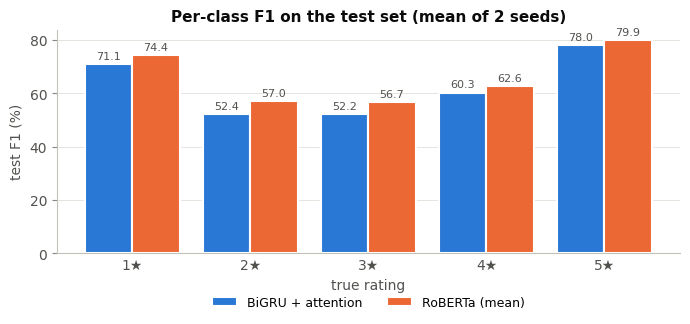

In [5]:
from common import figures_dir
from common.plotting import plot_grouped_bars

per_class = {model: {f"{star}★": 100 * summary[model]["per_class_f1"]["mean"][k] for k, star in enumerate(STAR_LABELS)}
             for model in (BASELINE, MAIN)}
plot_grouped_bars(per_class, ylabel="test F1 (%)", xlabel="true rating",
                  out_path=figures_dir(2) / "test_per_class_f1.png" if LIMIT is None else None,
                  title="Per-class F1 on the test set (mean of 2 seeds)")

## 4. Ablation: mean vs first-token pooling

Pooling was compared on validation during training (`03_roberta.ipynb`); the test columns confirm whether the difference holds on unseen data. A difference smaller than the seed-to-seed standard deviation should not be read as a real effect.

In [6]:
from common import load_json

ablation_rows = []
for model in (MAIN, ABLATION):
    val = [load_json(results_dir(2) / run / "summary.json")["val"] for run in RUNS[model]]
    ablation_rows.append({"pooling": model,
                          "val macro-F1 (%)": format_mean_std([v["macro_f1"] for v in val], scale=100),
                          "test macro-F1 (%)": format_mean_std(summary[model]["macro_f1"]["values"], scale=100),
                          "test accuracy (%)": format_mean_std(summary[model]["accuracy"]["values"], scale=100),
                          "test MAE (stars)": format_mean_std(summary[model]["mae"]["values"], digits=3)})
Markdown(markdown_table(ablation_rows))

| pooling | val macro-F1 (%) | test macro-F1 (%) | test accuracy (%) | test MAE (stars) |
|---|---|---|---|---|
| RoBERTa (mean) | 66.41 ± 0.06 | 66.11 ± 0.02 | 66.31 ± 0.01 | 0.378 ± 0.001 |
| RoBERTa (first token) | 66.91 ± 0.30 | 66.36 ± 0.18 | 66.54 ± 0.17 | 0.376 ± 0.002 |

## 5. Normalised confusion matrices

Rows are the true rating and each row sums to 1, so a cell reads as "share of true *i*-star reviews predicted as *j* stars". Counts are pooled over both seeds.

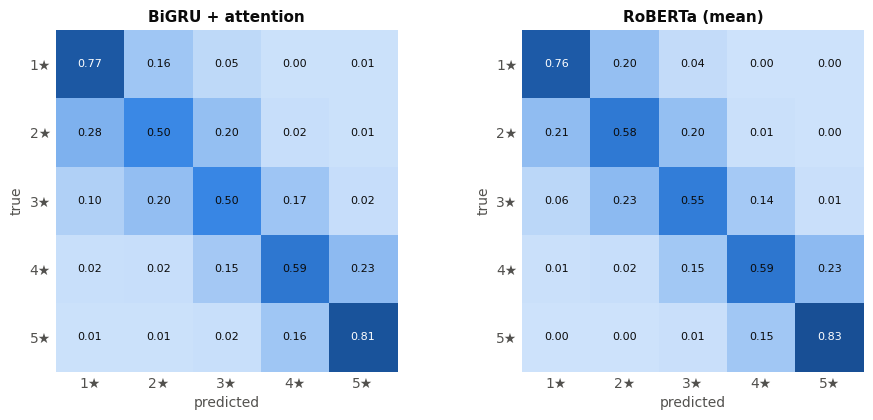

In [7]:
import matplotlib.pyplot as plt
from common.plotting import plot_confusion_matrix, savefig

fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.3))
for ax, model in zip(axes, (BASELINE, MAIN)):
    pooled = np.sum([metrics[r]["confusion_matrix"] for r in RUNS[model]], axis=0)
    plot_confusion_matrix(pooled, [f"{s}★" for s in STAR_LABELS], title=model, ax=ax)
fig.tight_layout()
if LIMIT is None:
    savefig(fig, figures_dir(2) / "test_confusion_matrices.png")
fig

## 6. Adjacent vs distant errors

Ratings are ordinal, so a 4★ review predicted as 5★ is a much smaller mistake than a 1★ review predicted as 5★. The first table splits every model's predictions by how many stars they are off (share of all test reviews); the second counts confusions between specific pairs of ratings, in both directions.

| model | exact (%) | off by 1 (%) | off by 2 (%) | off by 3 (%) | off by 4 (%) | adjacent share of errors (%) |
|---|---|---|---|---|---|---|
| BiGRU + attention | 63.30 ± 0.20 | 30.89 ± 0.10 | 4.89 ± 0.10 | 0.69 ± 0.07 | 0.23 ± 0.07 | 84.17 ± 0.18 |
| RoBERTa (mean) | 66.31 ± 0.01 | 30.12 ± 0.06 | 3.11 ± 0.04 | 0.35 ± 0.04 | 0.11 ± 0.01 | 89.40 ± 0.21 |
| RoBERTa (first token) | 66.54 ± 0.17 | 29.93 ± 0.07 | 3.05 ± 0.16 | 0.35 ± 0.07 | 0.13 ± 0.01 | 89.45 ± 0.24 |

| model | 1★↔2★ | 2★↔3★ | 3★↔4★ | 4★↔5★ | 1★↔3★ | 3★↔5★ | 1★↔5★ |
|---|---|---|---|---|---|---|---|
| BiGRU + attention | 439.0 | 404.0 | 313.5 | 388.0 | 155.5 | 44.0 | 11.5 |
| RoBERTa (mean) | 407.0 | 429.0 | 291.5 | 378.5 | 99.5 | 27.5 | 5.5 |
| RoBERTa (first token) | 404.0 | 416.0 | 290.0 | 386.5 | 97.0 | 26.0 | 6.5 |

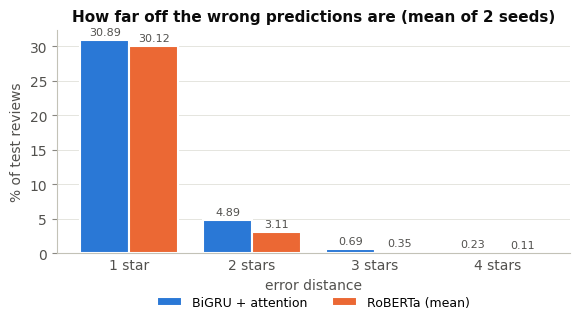

In [8]:
from q2.metrics import confusions_between, error_distances

distance_rows, pair_rows, distance_bars = [], [], {}
pairs = [(0, 1), (1, 2), (2, 3), (3, 4), (0, 2), (2, 4), (0, 4)]
for model, runs in RUNS.items():
    shares = np.array([error_distances(labels, [r["pred"] for r in preds[run]]) for run in runs])
    distance_rows.append({"model": model, **{("exact" if d == 0 else f"off by {d}") + " (%)": format_mean_std(shares[:, d], scale=100)
                                            for d in range(5)},
                          "adjacent share of errors (%)": format_mean_std(summary[model]["adjacent_share_of_errors"]["values"], scale=100)})
    pair_rows.append({"model": model, **{f"{a + 1}★↔{b + 1}★": np.mean([confusions_between(metrics[r]["confusion_matrix"], a, b) for r in runs])
                                         for a, b in pairs}})
    if model in (BASELINE, MAIN):
        distance_bars[model] = {f"{d} star{'s' if d > 1 else ''}": 100 * shares[:, d].mean() for d in range(1, 5)}
display(Markdown(markdown_table(distance_rows)))
display(Markdown(markdown_table(pair_rows, floatfmt=".1f")))
plot_grouped_bars(distance_bars, ylabel="% of test reviews", xlabel="error distance", value_format="{:.2f}",
                  out_path=figures_dir(2) / "test_error_distance.png" if LIMIT is None else None,
                  title="How far off the wrong predictions are (mean of 2 seeds)")

## 7. Where the models differ

A review counts as *RoBERTa right, BiGRU wrong* only when **both** RoBERTa (mean) seeds are right and **both** BiGRU seeds are wrong, and the other way round, so the examples aren't one seed's luck.

Each review gets rough tags for the phenomena the brief names: negation, mixed sentiment / contrast ("but", "however", ...), long reviews (more than 120 tokens, about the 95th percentile), and rare words or typos (two or more words outside the BiGRU's vocabulary). The tags are word patterns, not judgements, and sarcasm can't be caught by a pattern, so read the examples before describing them in the report. The first table shows how each model does on every tagged group of the test set.

In [9]:
from q2.evaluation import pick_examples, review_tags

unknown = [sum(t == vocab.unk_id for t in ids) for ids in classic_test["ids"]]
tags = [review_tags(text, n, u) for text, n, u in zip(texts, classic_test["n_tokens"], unknown)]


def accuracy_on(model, idx):
    return np.mean([np.mean([preds[r][i]["pred"] == labels[i] for i in idx]) for r in RUNS[model]])


tag_rows = []
for tag in ("negation", "mixed / contrast", "long", "rare words / typos", None):
    idx = [i for i, t in enumerate(tags) if (tag in t if tag else not t)]
    if idx:
        tag_rows.append({"group": tag or "no tag", "reviews": len(idx),
                         **{f"{m} acc (%)": 100 * accuracy_on(m, idx) for m in (BASELINE, MAIN)}})
Markdown(markdown_table(tag_rows, floatfmt=".1f"))

| group | reviews | BiGRU + attention acc (%) | RoBERTa (mean) acc (%) |
|---|---|---|---|
| negation | 2858 | 60.1 | 63.5 |
| mixed / contrast | 1905 | 56.6 | 60.3 |
| long | 216 | 57.2 | 60.0 |
| rare words / typos | 158 | 59.8 | 66.1 |
| no tag | 1539 | 70.1 | 72.8 |

In [10]:
def right(model, i):
    return all(preds[r][i]["pred"] == labels[i] for r in RUNS[model])


def wrong(model, i):
    return all(preds[r][i]["pred"] != labels[i] for r in RUNS[model])


def example(i, winner):
    return {"id": test["id"][i], "text": texts[i], "stars": labels[i] + 1, "tags": tags[i],
            "bigru_stars": [preds[r][i]["pred"] + 1 for r in RUNS[BASELINE]],
            "roberta_stars": [preds[r][i]["pred"] + 1 for r in RUNS[MAIN]],
            "confidence": float(np.mean([preds[r][i]["probs"][labels[i]] for r in RUNS[winner]]))}


roberta_wins = [example(i, MAIN) for i in range(len(test)) if right(MAIN, i) and wrong(BASELINE, i)]
bigru_wins = [example(i, BASELINE) for i in range(len(test)) if right(BASELINE, i) and wrong(MAIN, i)]
print(f"RoBERTa right, BiGRU wrong: {len(roberta_wins)} reviews; BiGRU right, RoBERTa wrong: {len(bigru_wins)} reviews")
chosen = {"roberta_right_bigru_wrong": pick_examples(roberta_wins, 6), "bigru_right_roberta_wrong": pick_examples(bigru_wins, 3)}
if LIMIT is None:
    save_json({"counts": {"roberta_right_bigru_wrong": len(roberta_wins), "bigru_right_roberta_wrong": len(bigru_wins)},
               **chosen}, results_dir(2) / "test_examples.json")


def show(examples, heading):
    display(Markdown(f"### {heading}"))
    for e in examples:
        display(Markdown(f"**True {e['stars']}★** · BiGRU {e['bigru_stars']} · RoBERTa {e['roberta_stars']} · "
                         f"tags: {', '.join(e['tags']) or 'none'} · id `{e['id']}`\n\n> {e['text']}"))


show(chosen["roberta_right_bigru_wrong"], "RoBERTa right, BiGRU wrong")
show(chosen["bigru_right_roberta_wrong"], "BiGRU right, RoBERTa wrong")

RoBERTa right, BiGRU wrong: 242 reviews; BiGRU right, RoBERTa wrong: 158 reviews


### RoBERTa right, BiGRU wrong

**True 4★** · BiGRU [2, 5] · RoBERTa [4, 4] · tags: negation, mixed / contrast, rare words / typos · id `en_0501949`

> It’s big (2 in picture). Arrived at the end of July and on delivery time. The mat itself: The Good: -came with a free gym towel -came with straps and sleeve for storage -came with pvc pipe to roll it on -feels good -the price is good The Bad -the only issue i could see is the material probably would not be suitable for dropping weights on. But then again this is a yoga mat. Overall: 4.5/5

**True 5★** · BiGRU [3, 2] · RoBERTa [5, 5] · tags: negation, mixed / contrast, long · id `en_0753534`

> Works 100% on curling-ironed hair. I'm have thick curly hair that I have to apply a lot of heat to just to get it semi-straight. And because I use only coconut oil it tends to leave my hair with a cooked kind of smell. This spray works! I sprayed my hair all over one time and it immediately cancelled the coconut odor out of my hair. The scent smells so nice and it's lightweight. I could smell it for about an hour or two and then it faded, but It totally canceled all the odor out of my hair...no more cooked smell. And I can use a little bit every day every time I curl my hair and it doesn't dry it out or change the texture whatsoever.

**True 3★** · BiGRU [4, 4] · RoBERTa [3, 3] · tags: negation, mixed / contrast, long, rare words / typos · id `en_0298106`

> A Society Advances at the Speed of Light. I'm still trying to remember why I liked Age of Myth, the first novel in this series. Whatever that was, it wasn't really present in the sequel. Though some of the characters are engaging and the overall story line is interesting enough, this book takes a few leaps that seemed forced in order to level the playing field between two races. A society going from the stone age to the copper age to the iron age (and discovering many of the technological and cultural advancements that come with those transitions) in a matter of weeks thanks to recurring epiphanies by two or three characters... well, let's just say it's all a bit rushed and bordering on repeated examples of deus ex machina (a phrase I've never used before, but which seems entirely appropriate in this case). Sadly, this book--which the author admitted is his favorite in the series--has me questioning whether to continue to Book Three.

...

**True 4★** · BiGRU [3, 3] · RoBERTa [4, 4] · tags: negation, mixed / contrast · id `en_0792507`

> 2018 Honda Accord. . Fit my 2018 Accord pretty good the back part of the seat isnt fully covered completely but most is, Came a bit wrinkled but not to bad, material is actually good quality

### BiGRU right, RoBERTa wrong

**True 1★** · BiGRU [1, 1] · RoBERTa [2, 2] · tags: negation · id `en_0133223`

> Not fully described. Amazon did't disclose the return policy of restock fee which is called cheating.

**True 1★** · BiGRU [1, 1] · RoBERTa [3, 2] · tags: negation, mixed / contrast · id `en_0239182`

> Probably very good, but my boy won't eat them. I hate to give this product one star when it probably deserves 5. My dog has chronic itchy skin and I had high hopes that this product would be the answer to his skin issues. I'll never know because he won't eat them. At first I gave them to him as a treat. He sniffed it and walked away. I crumbled just one up in his food but he was onto me and wouldn't touch it. So, sadly, the search continues.

**True 1★** · BiGRU [1, 1] · RoBERTa [2, 2] · tags: negation, mixed / contrast, long · id `en_0648962`

> ***Only works if you pay for subscription***. I’ve had my outdoor nest camera on my front porch for one year now. My subscription just ran out which is $100 per year. The camera is pretty useless without the subscription. When you have the subscription I can distinguish people from Pats or motion of trees blowing in the wind and sounds versus voices. Now that my subscription is over it can’t do any of those things is just notifies me anytime there’s motion and it can’t distinguish. It doesn’t even routine video for five minutes so you can go back and look and see who was on your porch because by time you receive the notification there already gone so the live feed is really ineffective unless someone hangs out in front of the camera for an extended period. So if you’re comfortable with being stuck with a subscription every year at $100 per camera then it is a decent camera but it’s useless without the subscription. I’m looking into other cameras where I don’t have to have a subscription.

## 8. What the models look at

For RoBERTa, **integrated gradients** (Sundararajan et al., 2017) attribute the logit of the predicted class to the input tokens: the embeddings are moved in 256 steps from a baseline (every token replaced by `<pad>`, `<s>` and `</s>` kept) to the real review, and the gradients along the way are summed per token. Unlike raw attention weights, the attributions add up to the change in the logit (the completeness gap printed below should be small). Sub-word pieces are summed into words, and the plot shows the positive part (evidence *for* the predicted rating), normalised to sum to 1. The strongest evidence *against* is printed.

For the BiGRU the attention pooling weights $\alpha_t$ are shown directly. They say which GRU states were pooled, which is related to but not the same as which words changed the prediction.

The examples are the first two short *RoBERTa right, BiGRU wrong* reviews from section 7, using the seed-42 models. Each is drawn twice: as heat strips, and as wrapped text with every word shaded by its weight, which stays readable at page width (the report uses that one). The weights are saved to `outputs/results/test_token_importance.json`, so the figures can be redrawn without the checkpoints.

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


example 1: true 5★, BiGRU 4★, RoBERTa 5★ | IG completeness gap +0.1222 on a logit change of +4.823
  most for:     Recommend. (+1.90), coffee. (+0.67), than (+0.50), pods. (+0.35), better (+0.32), Senseo, (+0.32)
  most against: this (-0.41), contains (-0.32), almost (-0.20), packaging (-0.18)


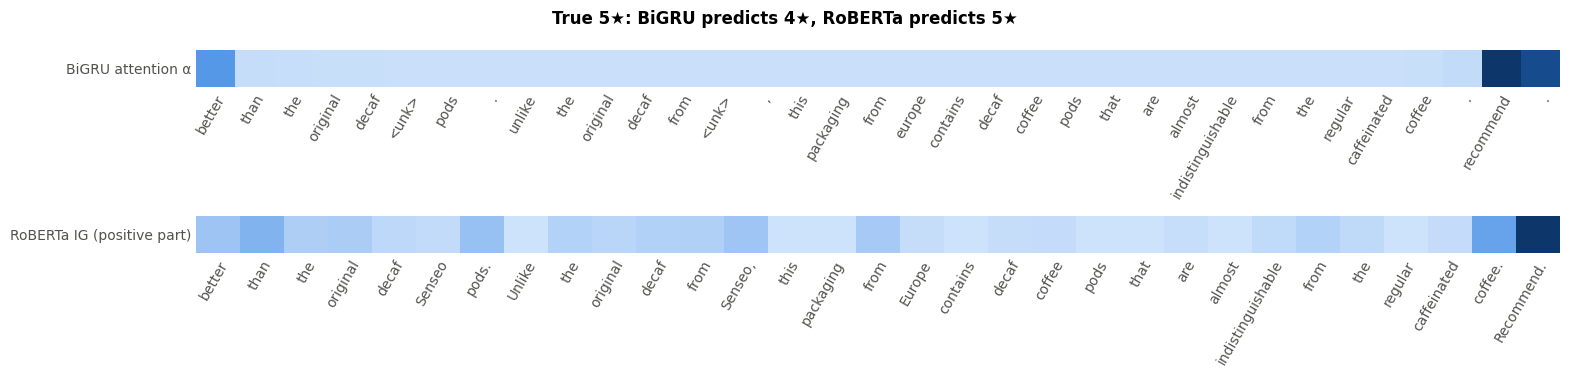

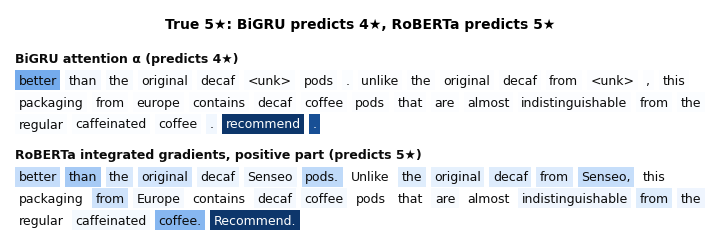

example 2: true 5★, BiGRU 1★, RoBERTa 5★ | IG completeness gap +0.0388 on a logit change of +4.238
  most for:     gone!! (+1.09), I’m (+0.65), cravings (+0.42), this, (+0.41), cravings (+0.35), I’m (+0.30)
  most against: don’t (-0.62), horrible (-0.41), are (-0.21), sure (-0.17)


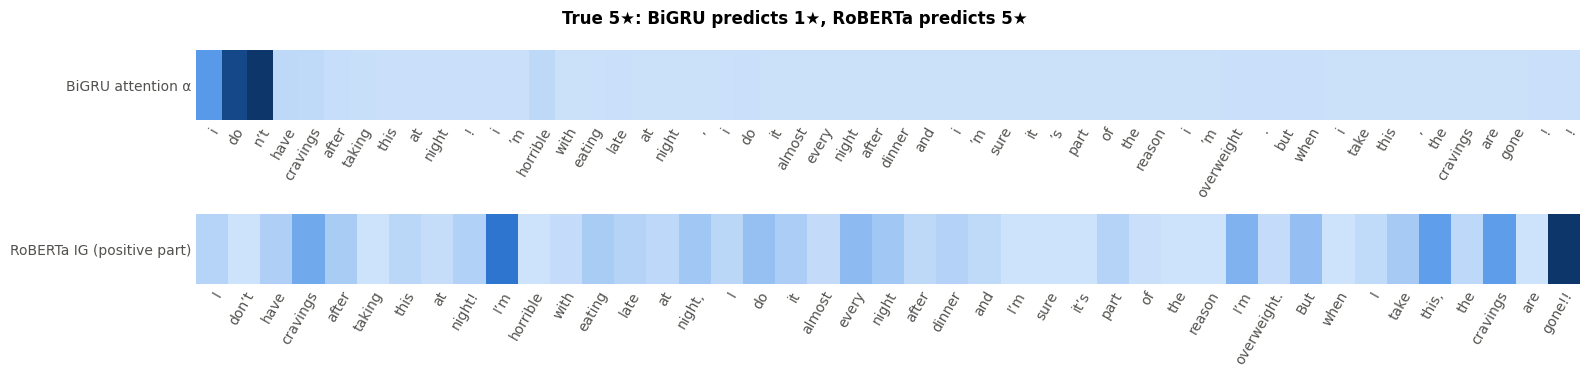

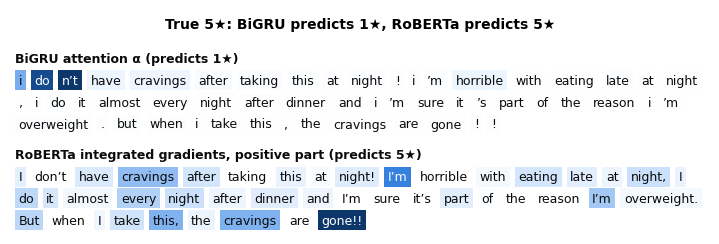

In [11]:
from q2.evaluation import integrated_gradients, merge_subwords, plot_token_highlights, plot_token_importance

bigru, roberta = load_bigru(RUNS[BASELINE][0], vocab).to(device), load_roberta(RUNS[MAIN][0]).to(device)
by_id = {review_id: i for i, review_id in enumerate(test["id"])}
explained = [e for e in chosen["roberta_right_bigru_wrong"] if len(e["text"].split()) <= 60][:2] or chosen["roberta_right_bigru_wrong"][:1]
importance = []

for k, e in enumerate(explained, start=1):
    i = by_id[e["id"]]
    ids = torch.tensor([classic_test["ids"][i]], device=device)
    with torch.no_grad():
        logits, alpha = bigru(ids, torch.tensor([ids.shape[1]], device=device), return_attention=True)
    bigru_tokens = [vocab.itos[t] for t in classic_test["ids"][i]]

    input_ids = torch.tensor([roberta_test["input_ids"][i]], device=device)
    target = int(roberta(input_ids, torch.ones_like(input_ids)).argmax())
    attributions, gap = integrated_gradients(roberta, input_ids, target, pad_id=tokenizer.pad_token_id)
    words, scores = merge_subwords(tokenizer.convert_ids_to_tokens(input_ids[0].tolist()), attributions.cpu(),
                                   tokenizer.convert_tokens_to_string)
    positive = np.clip(scores, 0, None) / max(np.clip(scores, 0, None).sum(), 1e-9)
    bigru_stars = int(logits.argmax()) + 1
    title = f"True {e['stars']}★: BiGRU predicts {bigru_stars}★, RoBERTa predicts {target + 1}★"

    print(f"example {k}: true {e['stars']}★, BiGRU {bigru_stars}★, RoBERTa {target + 1}★ | "
          f"IG completeness gap {gap:+.4f} on a logit change of {attributions.sum() - gap:+.3f}")
    order = np.argsort(scores)
    print("  most for:    ", ", ".join(f"{words[j]} ({scores[j]:+.2f})" for j in order[::-1][:6]))
    print("  most against:", ", ".join(f"{words[j]} ({scores[j]:+.2f})" for j in order[:4] if scores[j] < 0))
    display(plot_token_importance(
        [("BiGRU attention α", bigru_tokens, alpha[0].cpu().numpy()), ("RoBERTa IG (positive part)", words, positive)],
        out_path=figures_dir(2) / f"test_token_importance_{k}.png" if LIMIT is None else None, title=title))
    display(plot_token_highlights(
        [(f"BiGRU attention α (predicts {bigru_stars}★)", bigru_tokens, alpha[0].cpu().numpy()),
         (f"RoBERTa integrated gradients, positive part (predicts {target + 1}★)", words, positive)],
        out_path=figures_dir(2) / f"test_token_highlights_{k}.png" if LIMIT is None else None, title=title))
    importance.append({"id": e["id"], "stars": e["stars"], "bigru_stars": bigru_stars, "roberta_stars": target + 1,
                       "bigru_tokens": bigru_tokens, "bigru_attention": [round(float(a), 5) for a in alpha[0].cpu()],
                       "roberta_words": words, "roberta_ig": [round(float(s), 5) for s in scores],
                       "ig_completeness_gap": round(gap, 5)})

if LIMIT is None:
    save_json(importance, results_dir(2) / "test_token_importance.json")

## 9. Keeping the Kaggle output small

On Kaggle everything under `/kaggle/working` becomes the version's output. The checkpoints were only copied in from the attached training notebooks, which keep them, and `data/` is a download cache, so neither is saved again. Nothing is removed outside Kaggle.

In [12]:
import shutil
from common import data_dir

if Path("/kaggle/working").exists():
    for folder in (checkpoints_dir(2, create=False), data_dir(2, create=False)):
        shutil.rmtree(folder, ignore_errors=True)
    print("removed the copied checkpoints and the data cache from the output")

removed the copied checkpoints and the data cache from the output
